In [29]:
from typing import List, TypedDict
from langgraph.graph import StateGraph, START , END



In [30]:
class AgentState(TypedDict):
    number:int
    status: str
    lower:int
    upper:int
    guesses: List[int]



In [31]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [32]:
import numpy as np

In [33]:
def guess_node(state:AgentState) -> AgentState:
    state['guesses']=state['guesses'] + [np.random.randint(state['lower'], state['upper'] + 1)]
    return state

def judge_node(state:AgentState) ->AgentState:
    if(state['guesses'][-1]<state['number']):
        state['status']="<"
    elif(state['guesses'][-1]>state['number']):
        state['status']=">"
    else: state['status']="="
    return state

def reigenforcer_node(state:AgentState) -> AgentState:
    if state['status'] == "<":
        state['lower'] = state['guesses'][-1]+1 
    elif state['status'] == ">":
        state['upper'] = state['guesses'][-1]-1
    return state

def condition_node(state: AgentState) -> AgentState:
    if len(state['guesses']) < 7:
       if state['status'] == "=":
            return "success"
       return "loop"
    else:
        if state["status"] == "=":
            return "success"
        return "failed"


In [34]:
def success_node(state:AgentState) -> AgentState:
    print("Success! Guessed the number in ",len(state['guesses'])," tries.")
    return state

def failed_node(state:AgentState) -> AgentState:
    print("Failed! Could not guess the number in 7 tries.")
    return state

In [35]:
graph = StateGraph(AgentState)

graph.add_node("guesser" , guess_node)
graph.add_node("judge" , judge_node)
graph.add_node("reinforcer" , reigenforcer_node)
graph.add_node("router" , lambda state:state)
graph.add_node("success" , success_node)
graph.add_node("failed" , failed_node)

graph.add_edge(START,"guesser")
graph.add_edge("guesser" , "judge" )
graph.add_edge("judge" , "reinforcer")

graph.add_conditional_edges(
    "router",
    condition_node,
    {
        "loop": "guesser",
        "success": "success",
        "failed": "failed"
    }
)

graph.add_edge("reinforcer" , "router")
graph.add_edge("success" , END)
graph.add_edge("failed" , END)

app = graph.compile()

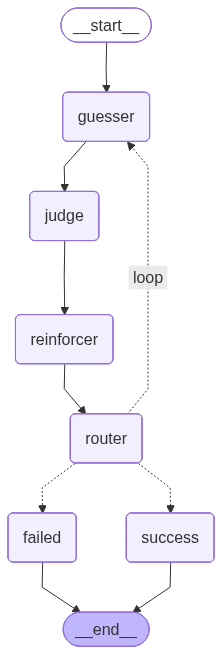

In [36]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [38]:
result = app.invoke({"number": 22, "status": "", "lower": 1, "upper": 50, "guesses": []})
print(result)

Success! Guessed the number in  3  tries.
{'number': 22, 'status': '=', 'lower': 19, 'upper': 29, 'guesses': [30, 18, 22]}


In [2]:
%pip install langchain_openai

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 8.8 MB/s  0:00:00
   ---------------------------------------- 0.0/876.5 kB ? eta -:--:--
   ---------------------------------------- 876.5/876.5 kB 19.8 MB/s  0:00:00

   ------ --------------------------------- 1/6 [regex]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   -------------------------- ------------- 4/6 [openai]
   ----------------------

In [3]:
%pip install dotenv


   ---------------------------------------- 2/2 [dotenv]

Note: you may need to restart the kernel to use updated packages.
